# [Тема проекта]: анализ и прогнозирование цен подержанных автомобилей

**Команда №** [__]

| Участник | Группа |
|---|---|
| [Фамилия И.] | [ФМ__-_] |
| [Фамилия И.] | [ФМ__-_] |
| [Фамилия И.] | [ФМ__-_] |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

## 1. Описание данных

In [2]:
df = pd.read_excel('Автомобили.xlsx')
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (700, 13)


,Производитель,Модель,"Возраст автомобиля, лет","Пробег, миль",Состояние,Тип кузова,Тип топлива,Электромобиль,Коробка передач,Привод,Количество цилиндров,Цвет,"Цена, USD"
0,Ford,super duty f-250 srw,5,118000,Отличное,Грузовик,Дизель,Нет,Автоматическая,Полный,8.0,Черный,43900
1,Chevrolet,silverado 1500,4,133329,Хорошее,Грузовик,Бензин,Нет,Автоматическая,Полный,8.0,Серебристый,26990
2,Ford,thunderbird,18,33970,Отличное,Кабриолет,Бензин,Нет,Автоматическая,Задний,8.0,Красный,18990
3,Ford,f150 platinum 4x4,9,175489,Как новый,Пикап,Бензин,Нет,Автоматическая,Полный,NaN,Черный,14777
4,Tesla,model 3,3,18900,Отличное,Седан,Электричество,Да,Другое,Задний,0.0,Белый,42200


- **Тема датасета:** объявления о продаже подержанных автомобилей на американском рынке: марка и модель, возраст, пробег, техническое состояние, характеристики кузова и двигателя, цена.
- **Одно наблюдение:** одно объявление о продаже конкретного автомобиля.
- **Источник:** [уточнить] открытый датасет объявлений о продаже б/у автомобилей (Craigslist, Kaggle). Предобработка до нас: из исходного массива отобрано 700 объявлений и 13 признаков, названия признаков и категорий переведены на русский, год выпуска пересчитан в возраст автомобиля.
- **Размер:** 700 наблюдений и 13 признаков.
- **Целевой признак:** `Цена, USD` – цена автомобиля в долларах. Признак количественный, поэтому для его прогноза используется линейная регрессия.

## 2. Описание признаков

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Производитель            700 non-null    str    
 1   Модель                   700 non-null    str    
 2   Возраст автомобиля, лет  700 non-null    int64  
 3   Пробег, миль             700 non-null    int64  
 4   Состояние                700 non-null    str    
 5   Тип кузова               700 non-null    str    
 6   Тип топлива              700 non-null    str    
 7   Электромобиль            700 non-null    str    
 8   Коробка передач          700 non-null    str    
 9   Привод                   660 non-null    str    
 10  Количество цилиндров     673 non-null    float64
 11  Цвет                     682 non-null    str    
 12  Цена, USD                700 non-null    int64  
dtypes: float64(1), int64(3), str(9)
memory usage: 71.2 KB


| № | Признак | Описание | Формат (pandas) | Тип данных |
|---|---|---|---|---|
| 1 | Производитель | Марка автомобиля (Ford, Toyota, Tesla и т.д.) | object | Категориальный номинальный |
| 2 | Модель | Модель автомобиля | object | Категориальный номинальный |
| 3 | Возраст автомобиля, лет | Сколько лет прошло с года выпуска | int64 | Количественный дискретный |
| 4 | Пробег, миль | Пробег по одометру | int64 | Количественный непрерывный |
| 5 | Состояние | Техническое состояние: Аварийное < Удовлетворительное < Хорошее < Отличное < Как новый < Новый | object | Категориальный порядковый |
| 6 | Тип кузова | Седан, внедорожник, пикап и т.д. | object | Категориальный номинальный |
| 7 | Тип топлива | Бензин, дизель, гибрид, электричество, другое | object | Категориальный номинальный |
| 8 | Электромобиль | Является ли автомобиль электромобилем (Да/Нет) | object | Категориальный бинарный |
| 9 | Коробка передач | Автоматическая, механическая, другое | object | Категориальный номинальный |
| 10 | Привод | Передний, задний, полный | object | Категориальный номинальный |
| 11 | Количество цилиндров | Число цилиндров двигателя (0 у электромобилей) | float64 | Количественный дискретный |
| 12 | Цвет | Цвет кузова | object | Категориальный номинальный |
| 13 | Цена, USD | Цена продажи в долларах (**целевой признак**) | int64 | Количественный непрерывный |

**Комментарии к классификации:**

- `Количество цилиндров` считается в целых единицах, но имеет формат `float64`: в признаке есть пропуски (`NaN`), а `NaN` в pandas – это значение типа float, целочисленный `int64` его хранить не может. Поэтому весь столбец приводится к `float64`. По смыслу признак количественный дискретный.
- `Состояние` – единственный порядковый признак: его категории выстраиваются в осмысленную последовательность от худшего к лучшему. У остальных категориальных признаков порядка нет (нельзя сказать, что «белый» больше «синего»).
- `Электромобиль` – бинарный: ровно два значения, Да и Нет.
- `Пробег` и `Цена` отнесены к непрерывным: это измеряемые величины, которые могут принимать любое значение на интервале, а целые числа в данных – результат округления.

## 3. Пропуски и дубликаты

In [4]:
missing = pd.DataFrame({
    'Количество пропусков': df.isna().sum(),
    'Доля пропусков, %': (df.isna().mean() * 100).round(2)
})
missing[missing['Количество пропусков'] > 0]

,Количество пропусков,"Доля пропусков, %"
Привод,40,5.71
Количество цилиндров,27,3.86
Цвет,18,2.57


In [5]:
print('Полных дубликатов строк:', df.duplicated().sum())

Полных дубликатов строк: 35


In [6]:
df_clean = df.drop_duplicates().copy()

df_clean['Привод'] = df_clean['Привод'].fillna(df_clean['Привод'].mode()[0])
df_clean['Цвет'] = df_clean['Цвет'].fillna(df_clean['Цвет'].mode()[0])
df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].fillna(
    df_clean['Количество цилиндров'].median())

df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].astype('int64')

print('Мода «Привод»:', df['Привод'].mode()[0])
print('Мода «Цвет»:', df['Цвет'].mode()[0])
print('Медиана «Количество цилиндров»:', df.drop_duplicates()['Количество цилиндров'].median())
print('Пропусков после заполнения:', df_clean.isna().sum().sum())
print('Размер df_clean:', df_clean.shape)

Мода «Привод»: Полный
Мода «Цвет»: Белый
Медиана «Количество цилиндров»: 6.0
Пропусков после заполнения: 0
Размер df_clean: (665, 13)


**Выводы:**

- Пропуски есть в трёх признаках: `Привод` – 40 (5.71%), `Количество цилиндров` – 27 (3.86%), `Цвет` – 18 (2.57%). Доля везде меньше 6%, поэтому строки не удаляем, а заполняем пропуски.
- Найдено 35 полных дубликатов строк. Это повторно размещённые объявления, они удалены. Дубликаты удаляются до заполнения пропусков, чтобы повторы не искажали моду и медиану.
- **Привод** и **Цвет** – категориальные номинальные признаки, заполняем **модой** (Полный и Белый). Для текстовых меток можно посчитать только частоту, поэтому мода – единственная применимая мера центральной тенденции: среднее и медиана для слов не существуют.
- **Количество цилиндров** – количественный дискретный признак, заполняем **медианой** (6). Среднее (5.59) дробное, а дробного числа цилиндров не бывает, к тому же оно чувствительно к крайним значениям (0 у электромобилей, 10 у мощных двигателей). Медиана устойчива к ним и даёт реальное значение. Мода (8) лишь самое частое значение и не отражает центр распределения, где много 4- и 6-цилиндровых моторов.
- После заполнения пропусков `Количество цилиндров` приведён к `int64`, так как причина формата `float64` (наличие `NaN`) устранена.
- Итог: **df_clean – 665 строк, 13 признаков, пропусков нет.**

## 4. Выбросы

### 4.1. Ящики с усами

/tmp/ipykernel_188/3604122332.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_clean[col], vert=False, patch_artist=True,
/tmp/ipykernel_188/3604122332.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_clean[col], vert=False, patch_artist=True,
/tmp/ipykernel_188/3604122332.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_clean[col], vert=False, patch_artist=True,
/tmp/ipykernel_188/3604122332.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_clean[col], vert=False, patch_artis

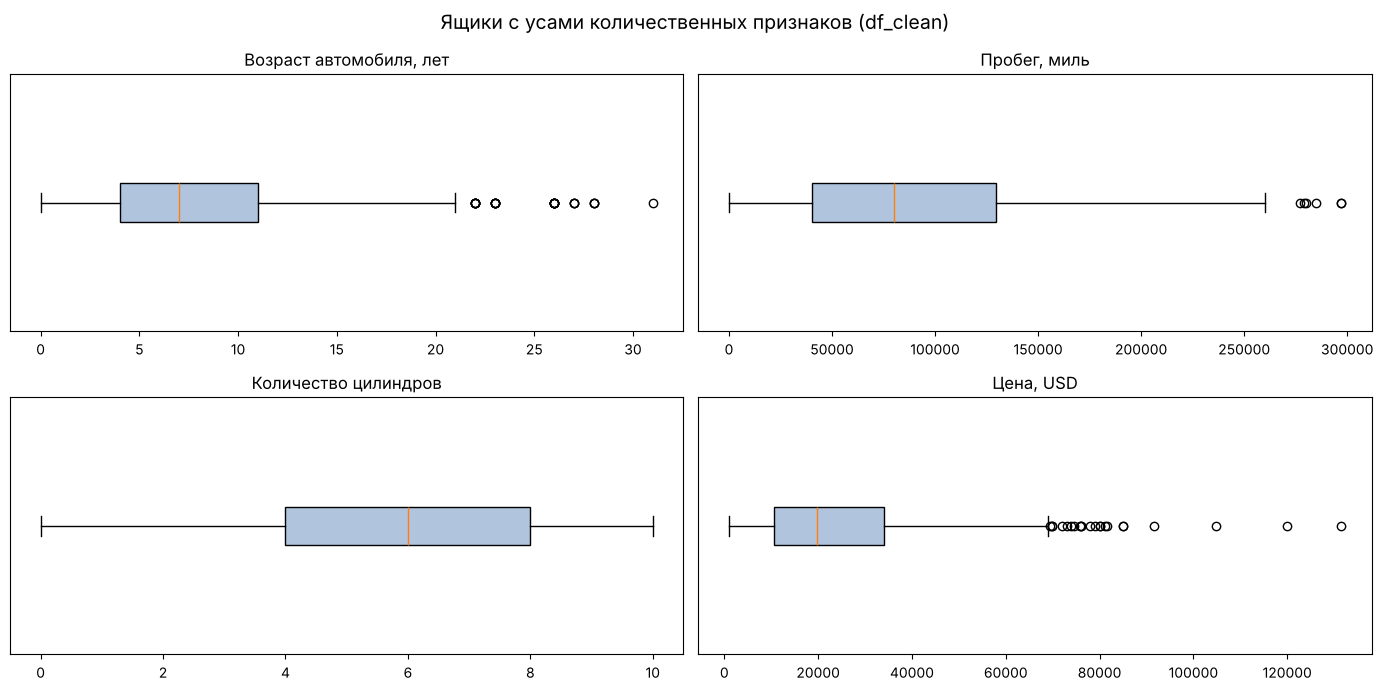

In [7]:
num_cols = ['Возраст автомобиля, лет', 'Пробег, миль', 'Количество цилиндров', 'Цена, USD']

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, col in zip(axes.flatten(), num_cols):
    ax.boxplot(df_clean[col], vert=False, patch_artist=True,
               boxprops=dict(facecolor='lightsteelblue'))
    ax.set_title(col)
    ax.set_yticks([])
plt.suptitle('Ящики с усами количественных признаков (df_clean)', fontsize=14)
plt.tight_layout()
plt.show()

**Выводы:**

- `Цена, USD` – 22 точки за правым усом (дороже ~69 тыс. USD), максимум 131 500 при медиане около 20 тыс. Распределение сильно скошено вправо.
- `Пробег, миль` – 6 выбросов справа, машины с пробегом выше ~264 тыс. миль.
- `Возраст автомобиля, лет` – 26 точек справа: машины старше 21 года. Три четверти автомобилей не старше 11 лет.
- `Количество цилиндров` – выбросов нет: все значения от 0 (электромобили) до 10 лежат внутри усов.
- Слева выбросов нет ни у одного признака, все хвосты направлены вправо.
- Параметр `vert=False` разворачивает ящики горизонтально: значения признака идут по оси X, так длинные хвосты удобнее читать.

### 4.2. Метод N стандартных отклонений

In [8]:
price = df_clean['Цена, USD']
N = 3
mean_p, std_p = price.mean(), price.std()
low_std, high_std = mean_p - N * std_p, mean_p + N * std_p

df_no_std = df_clean[(price >= low_std) & (price <= high_std)].copy()

print(f'Среднее: {mean_p:,.0f}, стандартное отклонение: {std_p:,.0f}')
print(f'Границы: {low_std:,.0f} ... {high_std:,.0f}')
print('Удалено строк:', len(df_clean) - len(df_no_std))
print('Размер df_no_std:', df_no_std.shape)

Среднее: 24,543, стандартное отклонение: 18,785
Границы: -31,811 ... 80,898
Удалено строк: 8
Размер df_no_std: (657, 13)


**Выводы:**

- Этим методом проверяем целевую переменную `Цена, USD`: ассистент рекомендовал отдельно проверить целевую, а предиктор почистим вторым методом в п. 4.3.
- Выбрано **N = 3**. При N = 3 за пределы интервала попадает около 0.3% наблюдений нормального распределения, то есть удаляются только явно аномальные значения. При N = 2 удалилось бы 30 строк (4.5% выборки), в том числе обычные дорогие, но реальные автомобили, а мы потеряли бы информацию для регрессии.
- Границы: **−31 811 ... 80 898 USD**. Удалено **8** автомобилей дороже 80 898 USD (от 81 250 до 131 500), это премиальные машины, нетипичные для выборки.
- Итог: **df_no_std – 657 строк.**

### 4.3. Метод 1.5 × IQR

In [9]:
mileage = df_no_std['Пробег, миль']
Q1, Q3 = mileage.quantile(0.25), mileage.quantile(0.75)
IQR = Q3 - Q1
low_iqr, high_iqr = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

df_final = df_no_std[(mileage >= low_iqr) & (mileage <= high_iqr)].copy()

print(f'Q1 = {Q1:,.0f}, Q3 = {Q3:,.0f}, IQR = {IQR:,.0f}')
print(f'Границы: {low_iqr:,.0f} ... {high_iqr:,.0f}')
print('Удалено строк:', len(df_no_std) - len(df_final))
print('Размер df_final:', df_final.shape)

Q1 = 42,616, Q3 = 129,960, IQR = 87,344
Границы: -88,400 ... 260,976
Удалено строк: 6
Размер df_final: (651, 13)


**Выводы:**

- Чистим предиктор `Пробег, миль`, данные берём уже из `df_no_std`.
- Q1 = 42 616, Q3 = 129 960, IQR = 87 344 мили. Границы: **−88 400 ... 260 976** миль.
- Удалено **6** автомобилей с пробегом выше 260 976 миль (до 297 тыс.). Такой пробег сильно выделяется на фоне остальных и может быть ошибкой ввода.
- Итог: **df_final – 651 строка.**

**Почему левая граница в обоих методах отрицательная:**

- Оба признака скошены вправо: основная масса значений сосредоточена у нуля, а длинный правый хвост сильно увеличивает разброс.
- В методе N·STD стандартное отклонение цены (18 785) большое относительно среднего (24 543), поэтому среднее − 3·std уходит ниже нуля. В методе IQR межквартильный размах (87 344) больше Q1 (42 616), поэтому Q1 − 1.5·IQR тоже отрицательная.
- Формулы симметричны относительно центра и не учитывают, что цена и пробег не бывают отрицательными. Значит, левая граница здесь ничего не отсекает и фактически работает только правая: выбросы в этих данных есть только сверху.

In [10]:
df_final.to_excel('df_final.xlsx', index=False)
print('Цепочка размеров:', len(df), '→', len(df_clean), '→', len(df_no_std), '→', len(df_final))

Цепочка размеров: 700 → 665 → 657 → 651
